# Data loading and exploration

# Q1: Load the Iris dataset using sklearn.datasets.load
_
iris() and print
feature
_
names, target
_
names, and the shape of data.

In [1]:
# Load the Iris dataset
from sklearn.datasets import load_iris
iris = load_iris()

In [8]:
# Printing
print("feature_names:", iris['feature_names'])
print("target_names:", iris['target_names'])
print("data shape:", iris['data'].shape)
print("iris.keys:",iris.keys())

feature_names: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
target_names: ['setosa' 'versicolor' 'virginica']
data shape: (150, 4)
iris.keys: dict_keys(['data', 'target', 'frame', 'target_names', 'DESCR', 'feature_names', 'filename', 'data_module'])


# Q2: Provide a short written answer: What type of problem is this
(classification/regression)? Why? Write your answer in a Markdown cell below.

# This is a classification problem, because the target is a discrete category , not a continuous number.

# Q3: Show the first five rows of the data as a pandas DataFrame with column names from
feature
names.

In [12]:
# Show first 5 rows as DataFrame
import pandas as pd
df = pd.DataFrame(iris['data'], columns=iris['feature_names'])
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


# Q4: Report class distribution (counts for each species)

In [13]:
pd.Series(iris['target']).map(dict(enumerate(iris['target_names']))).value_counts()

setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

# Visualization

# Q5: Create a pair plot (scatter plot matrix) for the four features using matplotlib. Color
points by species.

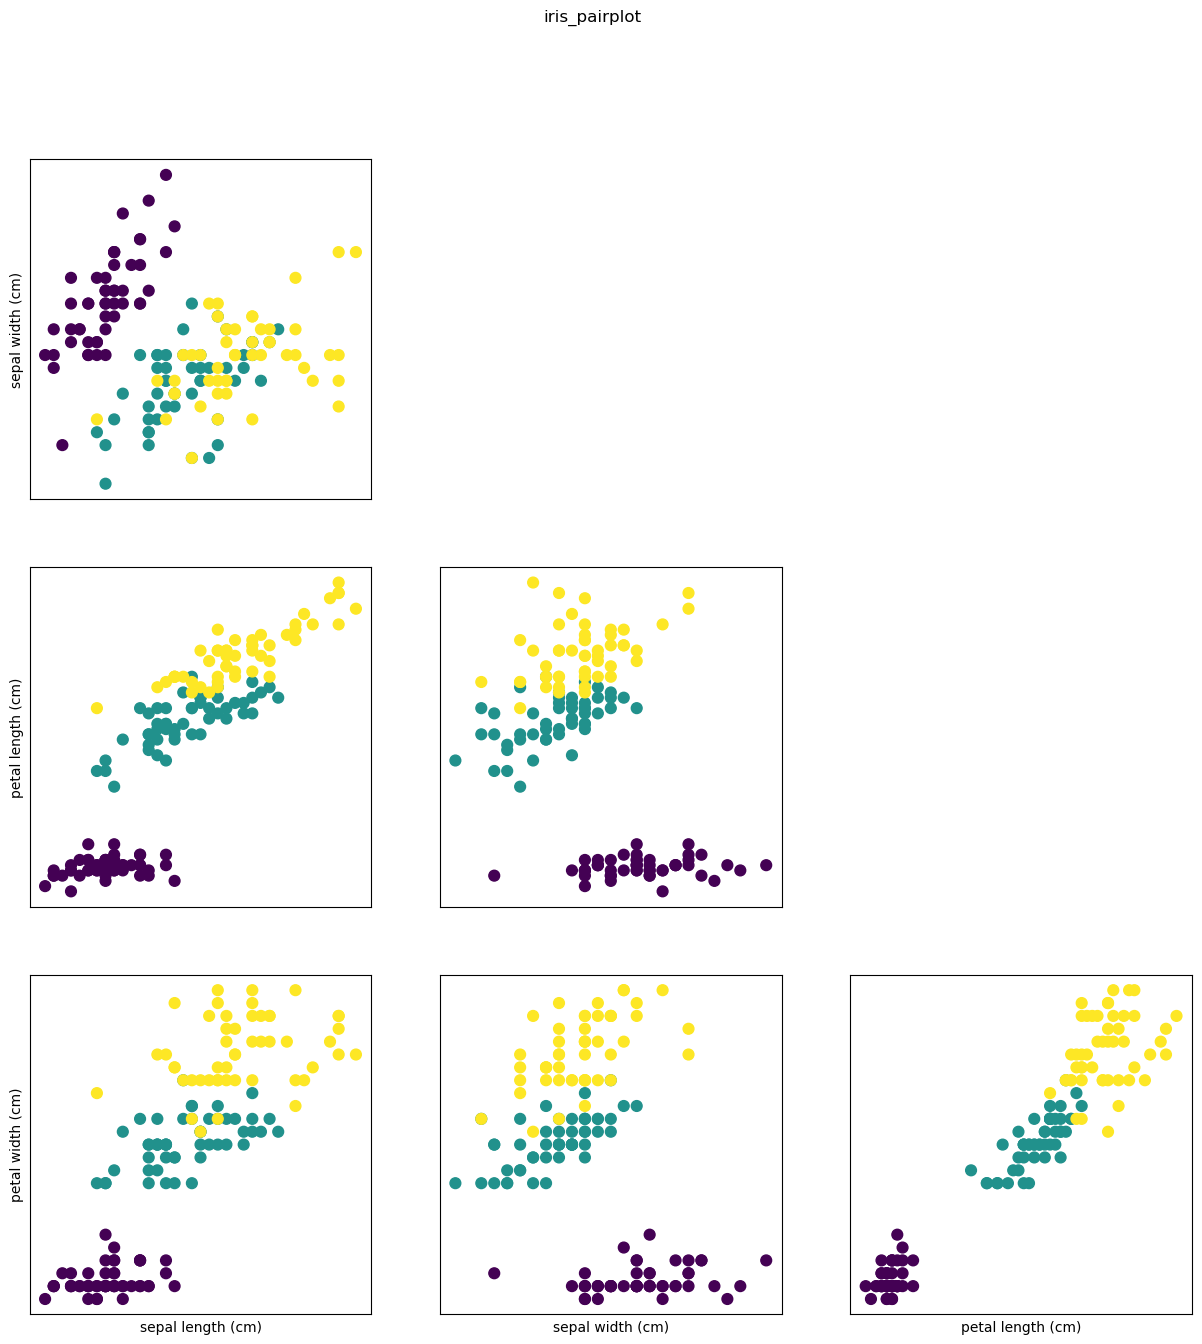

In [14]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(3, 3, figsize=(15, 15))
plt.suptitle("iris_pairplot")

for i in range(3):
    for j in range(3):
        ax[i, j].scatter(iris['data'][:, j], iris['data'][:, i + 1], c=iris['target'], s=60)
        ax[i, j].set_xticks(())
        ax[i, j].set_yticks(())
        if i == 2:
            ax[i, j].set_xlabel(iris['feature_names'][j])
        if j == 0:
            ax[i, j].set_ylabel(iris['feature_names'][i + 1])
        if j > i:
            ax[i, j].set_visible(False)
plt.show()

# Q6: Based on your plot, which two features appear most useful to separate the classes?
Explain in one short sentence.

# Petal length and petal width best separate the classes: setosa is clearly isolated, and versicolor and virginica overlap far less than in the sepal features.

# Train - Test - split and KNN modeling

# Q7: Split the data into train/test sets (75% train, 25% test). Use stratify=target and
random
_
state=42. Print shapes.

In [15]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    iris['data'], iris['target'], test_size=0.25, random_state=42, stratify=iris['target'])

In [19]:
print(X_train.shape)  # Print shapes
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(112, 4)
(38, 4)
(112,)
(38,)


# Q8: Train a KNeighborsClassifier with n
_
neighbors=3. Fit on training data and
report test accuracy.

In [17]:
# Train KNN
import numpy as np
from sklearn.neighbors import KNeighborsClassifier
knn = KNeighborsClassifier(n_neighbors=3)
knn.fit(X_train, y_train)

,n_neighbors,3
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [18]:
# and report accuracy
y_pred = knn.predict(X_test)
print(np.mean(y_pred == y_test))
print(knn.score(X_test, y_test))

0.9736842105263158
0.9736842105263158


# Q9: Compare accuracy for n
_
neighbors = 1, 3, 5. Report which k gives best accuracy
and why (short sentence).

In [20]:

for k in [1, 3, 5]:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train, y_train)
    print("k =", k, "accuracy =", model.score(X_test, y_test))

k = 1 accuracy = 0.9473684210526315
k = 3 accuracy = 0.9736842105263158
k = 5 accuracy = 0.9736842105263158


# Which k is best and why?

# k=3 and k=5 give the best accuracy (0.9737, about 97.4%), while k=1 is lower (0.9474).With k=1 the model relies on a single nearest neighbor, so it is sensitive to noise and outliers and can overfit. A slightly larger k averages over several neighbors, which gives a smoother decision boundary and generalizes better.

# Q10: Use your trained KNeighborsClassifier (use k=3) to predict the class of a new
sample with features: [5.0, 2.9, 1.0, 0.2]. Show predicted class name.

In [21]:
X_new = np.array([[5.0, 2.9, 1.0, 0.2]])
prediction = knn.predict(X_new)
print(iris['target_names'][prediction])

['setosa']
